# ECE780 Final Project：Diffuser 走廊堵塞改道（Colab 實驗 notebook）

**題目**：Training-Free Rerouting of a Pretrained Diffuser in Blocked Mazes
**狀態**：實驗全部完成（2026-11-11 主結果；2026-11-22 補 Oracle、部分堵塞、兩個消融）。所有結果存在 Google Drive 的 `ece780_diffuser_cache/results/`。
**裝置**：所有實驗都在 Colab **T4 GPU** 上跑（情境清單也是），之後若要補跑也必須用 T4。

## 結果總覽（每組 50 個情境）

| 方法 | 完全堵塞 | 部分堵塞 | 每回合抽樣數（完全） |
| --- | --- | --- | --- |
| B0：不 replan | 0% | 46% | 1 |
| B1：每 100 步 replan | 34% | 40% | 101 |
| B2：預測會撞才 replan，無地圖 | 20% | 36% | 194 |
| **Ours：B2 ＋ A* 換走廊 ＋ 分段走** | **76%** | **70%** | **54** |
| Oracle：已知地圖 A*＋PD（上限） | 100% | 100% | 1 |

- Ours vs B2 配對比較（完全堵塞）：只有 Ours 成功 28、只有 B2 成功 0（McNemar p ≈ 7e-9）
- 消融（完全堵塞，只換 Ours 的一個設計）：每個路口都設 waypoint 62%（碰撞 30%）；中間 inpainting 20%（98.8% 的計畫在 waypoint 出現尖刺）

## 這份 notebook 怎麼用

| 想做什麼 | 跑哪裡 | 要多久 |
| --- | --- | --- |
| 只看結果（表格、圖） | **A 區**，不用裝環境 | 1 分鐘 |
| 補跑或新增實驗 | **B 區（開機）全部**，再到 C 區找對應的格子 | 開機 10–15 分鐘 |
| 查某個實驗當時怎麼跑、輸出是什麼 | **C 區**（輸出都保留著，不用重跑） | — |

**C 區的格子都已經跑完，結果在 Drive 上。重跑會跳過已完成的回合，不會覆蓋結果；但不要重跑 C3（情境清單）。**

---
# A. 看結果（不用裝環境）

只要掛載 Google Drive，就能讀出所有結果。執行階段用 CPU 就可以。

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import json, os
from IPython.display import Image, display
RESULTS = '/content/drive/MyDrive/ece780_diffuser_cache/results'

def table(run):
    s = json.load(open(f'{RESULTS}/{run}/summary.json'))
    print(f"== {run}  ({s['n_common_scenarios']} paired scenarios)")
    print(f"{'method':7s} {'success':>8s} {'95% CI':>12s} {'collide':>8s} {'plans':>7s} {'plan s':>7s}  failures")
    for m, b in s['by_method'].items():
        lo, hi = b['success_95ci']
        print(f"{m:7s} {b['success_rate']:8.0%} {lo:5.0%}-{hi:5.0%} {b['obstacle_collision_rate']:8.0%} "
              f"{b['n_plans']['mean']:7.1f} {b['planning_time_s']['mean']:7.1f}  {b['failure_reasons']}")
    if 'ours_vs_b2' in s:
        print('Ours vs B2 (paired):', s['ours_vs_b2'])
    print()

for run in ['main', 'partial', 'ablation_junctions', 'ablation_inpaint']:
    if os.path.exists(f'{RESULTS}/{run}/summary.json'):
        table(run)

**資料夾對照**：`main` = 完全堵塞（主結果）、`partial` = 部分堵塞、`ablation_junctions` = 每個路口都設 waypoint、`ablation_inpaint` = 中間 inpainting。每個資料夾裡有 `episodes.csv`（每回合一列）、`summary.json`、`overview.png`，以及 `<方法>/episodes/<情境>.png`（每回合的軌跡圖）。

下面這格顯示長條圖，以及簡報用的對照圖 `full_s004`（B2 跟著穿牆的計畫卡住；Ours 經過 A* 選的 waypoint 成功）。

In [ ]:
for run in ['main', 'partial']:
    print(run); display(Image(f'{RESULTS}/{run}/overview.png', width=900))
for m in ['B2', 'Ours']:
    print(m, 'full_s004'); display(Image(f'{RESULTS}/main/{m}/episodes/full_s004.png', width=450))

---
# B. 開機（每次要跑實驗都從這裡開始）

Colab 每次重開，`/content` 都會清空，所以要依序跑完 B1–B10。資料集和權重存在 Drive，不會重新下載。

**開始前**：`執行階段 → 變更執行階段類型 → T4 GPU`。
程式都在 repo 的 `xinyi/rerouting` branch 上（B1 的 `BRANCH`），不用另外準備檔案。

任何一個「檢查」格失敗就停下來，先解決再往下。

## B1. 設定（只要改這格）
`TORCH_BUILD = 'cu111'`、`DEVICE = 'cuda'` 是用 T4 跑的設定，不要改；所有結果都是這樣跑出來的。

In [1]:
REPO_URL = 'https://github.com/ylin1202/Diffuser-Project.git'
BRANCH   = 'xinyi/rerouting'  # 程式都在這個 branch；合併進 main 之後改成 'main'
USE_DRIVE = True           # True：資料集與權重存在 Google Drive，斷線後不用重下
TORCH_BUILD = 'cu111'      # T4 GPU 用的 torch；所有結果都是這個設定
DEVICE = 'cuda'            # 實驗跑在 GPU 上；要跟已有結果比較就不要改
UPLOAD_ZIP = False         # 程式已經在 repo 上，不用上傳 zip；只有要測試還沒 push 的程式才改 True

import os
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CACHE = '/content/drive/MyDrive/ece780_diffuser_cache'
else:
    CACHE = '/content/cache'
os.makedirs(CACHE, exist_ok=True)
REPO_DIR = '/content/diffuser-project'
print('cache =', CACHE, '| repo =', REPO_DIR, '| branch =', BRANCH)

Mounted at /content/drive
cache = /content/drive/MyDrive/ece780_diffuser_cache | repo = /content/diffuser-project | branch = main


## B2. 系統套件（mujoco-py 編譯需要）

In [2]:
!apt-get -qq update
!for p in libosmesa6-dev libgl1-mesa-dev libglfw3 libglew-dev patchelf unzip; do apt-get install -y -qq $p > /dev/null 2>&1 && echo "ok $p" || echo "FAIL $p"; done
!ls /usr/include/GL/osmesa.h

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
ok libosmesa6-dev
ok libgl1-mesa-dev
ok libglfw3
ok libglew-dev
ok patchelf
ok unzip
/usr/include/GL/osmesa.h


## B3. MuJoCo 2.0、Python 3.8 環境、環境變數

In [3]:
%%bash
set -e
mkdir -p ~/.mujoco && cd ~/.mujoco
if [ ! -d mujoco200 ]; then
  wget -q https://www.roboti.us/download/mujoco200_linux.zip
  unzip -q mujoco200_linux.zip && mv mujoco200_linux mujoco200 && rm mujoco200_linux.zip
fi
[ -f mjkey.txt ] || wget -q https://www.roboti.us/file/mjkey.txt
cp mjkey.txt mujoco200/bin/ 2>/dev/null || true
ls ~/.mujoco

mjkey.txt
mujoco200


In [4]:
%%bash
set -e
if [ ! -d /content/mf ]; then
  wget -q https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh -O /tmp/mf.sh
  bash /tmp/mf.sh -b -p /content/mf > /dev/null
fi
[ -d /content/mf/envs/diffuser ] || /content/mf/bin/conda create -y -q -n diffuser python=3.8 > /dev/null
/content/mf/envs/diffuser/bin/python --version

Python 3.8.20


warning  libmamba Security Warning: This transaction includes executing package scripts (pre/post-link/unlink) if present. These scripts can contain arbitrary code. Please ensure you trust the package sources.
WARNING conda.conda_pypi.main:notify_conda_pypi_tip(158): 
  Did you know? You can install many PyPI packages with conda
  using conda-pypi. Get started:
    https://bit.ly/4xXYt0B



In [5]:
PY = '/content/mf/envs/diffuser/bin/python'
os.environ['PY'] = PY
os.environ['REPO_DIR'] = REPO_DIR
os.environ['LD_LIBRARY_PATH'] = '/root/.mujoco/mujoco200/bin:/usr/lib/nvidia:/usr/lib64-nvidia:' + os.environ.get('LD_LIBRARY_PATH', '')
os.environ['MUJOCO_PY_MJKEY_PATH'] = '/root/.mujoco/mjkey.txt'
os.environ['MUJOCO_PY_MUJOCO_PATH'] = '/root/.mujoco/mujoco200'
os.environ['MUJOCO_PY_FORCE_CPU'] = '1'
os.environ['MPLBACKEND'] = 'Agg'
os.environ['D4RL_SUPPRESS_IMPORT_ERROR'] = '1'
os.environ['D4RL_DATASET_DIR'] = CACHE + '/d4rl'
os.environ['PYTHONPATH'] = REPO_DIR
os.makedirs(os.environ['D4RL_DATASET_DIR'], exist_ok=True)
print('ok')

ok


## B4. 安裝套件（約 5 分鐘）
版本跟 repo 的 B0 README §5.1 一致；`--no-build-isolation`、`Cython<3`、舊 setuptools 都是必要的。

In [6]:
!$PY -m pip install "pip==23.0.1" "setuptools==65.5.0" "wheel==0.38.4" "Cython<3" numpy==1.23.5 2>&1 | tail -n 2
!$PY -m pip install --no-build-isolation gym==0.18.0 2>&1 | tail -n 2
!$PY -m pip install "glfw>=1.4" "cffi>=1.10" "fasteners~=0.15" "imageio>=2.1.2" 2>&1 | tail -n 1
!$PY -m pip install -v --no-build-isolation mujoco-py==2.0.2.13 2>&1 | grep -iE "error|fatal|Successfully" | head -n 20
if TORCH_BUILD == 'cpu':
    !$PY -m pip install torch==1.9.1+cpu -f https://download.pytorch.org/whl/torch_stable.html 2>&1 | tail -n 1
else:
    !$PY -m pip install torch==1.9.1+cu111 -f https://download.pytorch.org/whl/torch_stable.html 2>&1 | tail -n 1
!$PY -m pip install matplotlib==3.3.4 typed-argument-parser einops gitpython imageio scikit-video==1.1.11 h5py termcolor click tqdm pandas 2>&1 | tail -n 1
!$PY -m pip install "Pillow==7.2.0" 2>&1 | tail -n 1
!$PY -m pip install --no-deps "git+https://github.com/aravindr93/mjrl@master#egg=mjrl" 2>&1 | tail -n 1
!$PY -m pip install --no-deps "git+https://github.com/Farama-Foundation/d4rl@f2a05c0d66722499bf8031b094d9af3aea7c372b#egg=d4rl" 2>&1 | tail -n 1

      Successfully uninstalled pip-24.3.1
Successfully built mujoco-py


### 檢查 B4：要看到 `mujoco_py OK` 和 `cuda True`

In [7]:
!$PY -c "import mujoco_py; print('mujoco_py OK', mujoco_py.__version__)"
!$PY -c "import torch; print('torch', torch.__version__, 'cuda', torch.cuda.is_available())"

mujoco_py OK 2.0.2.13
torch 1.9.1+cu111 cuda True


## B5. 抓 repo、切到 `BRANCH`
程式、config、情境清單都已經在 repo 的 branch 上，不用再上傳 zip（除非 B1 把 `UPLOAD_ZIP` 改成 `True`）。

In [8]:
if not os.path.isdir(REPO_DIR + '/.git'):
    !git clone -q {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
!$PY -m pip -q install --no-deps -e .

/content/diffuser-project
  Preparing metadata (setup.py) ... done


In [9]:
%cd {REPO_DIR}
!git fetch -q origin && git checkout -q {BRANCH} && git pull -q origin {BRANCH}
!git log --oneline -3

/content/diffuser-project
ea1b336 (HEAD -> main, origin/main, origin/HEAD) Move experiments/common/env to experiments/common/setup
6c98692 Add B0 baseline experiment (Step 1): frozen Diffuser, plan once, no obstacle
63cf475 Initial commit: Diffuser maze2d source with CPU compatibility changes


In [23]:
# 只有 UPLOAD_ZIP = True 時才會跳出上傳視窗（測試還沒 push 的程式用）
if UPLOAD_ZIP:
    from google.colab import files
    up = files.upload()
    zip_name = list(up)[0]
    !unzip -o -q "{zip_name}" -d {REPO_DIR}
%cd {REPO_DIR}
!git status --short

## B6. 權重（從 Drive 連到 repo 的 `logs/`）

In [12]:
import glob, subprocess
zip_path = CACHE + '/maze2d-logs.zip'
if not os.path.exists(zip_path):
    subprocess.run(['wget', '-q', '-O', zip_path,
                    'https://www.dropbox.com/s/za14rwp8to1bosn/maze2d-logs.zip?dl=1'], check=True)
unz = CACHE + '/maze2d-logs'
if not os.path.isdir(unz):
    subprocess.run(['unzip', '-q', zip_path, '-d', unz], check=True)
hits = glob.glob(unz + '/**/maze2d-large-v1/diffusion/H384_T256/model_config.pkl', recursive=True)
assert hits, '找不到 large 權重，把下面 find 的結果貼回對話'
env_dir = os.path.dirname(os.path.dirname(os.path.dirname(hits[0])))   # .../maze2d-large-v1
os.makedirs(REPO_DIR + '/logs', exist_ok=True)
link = REPO_DIR + '/logs/maze2d-large-v1'
if not os.path.exists(link):
    os.symlink(env_dir, link)
!ls -la {link}/diffusion/H384_T256 | head

total 29565
drwx------ 2 root root     4096 Aug 11  2022 .
drwx------ 3 root root     4096 Jul 26  2022 ..
-rw------- 1 root root      280 Jul 27  2022 dataset_config.pkl
-rw------- 1 root root      313 Jul 27  2022 diffusion_config.pkl
-rw------- 1 root root     6148 Aug 11  2022 .DS_Store
-rw------- 1 root root      202 Jul 27  2022 model_config.pkl
-rw------- 1 root root      156 Jul 27  2022 render_config.pkl
-rw------- 1 root root    88514 Jul 30  2022 sample-1999000-0.png
-rw------- 1 root root    78447 Jul 30  2022 sample-1999000-1.png


## B7. 資料集

In [13]:
!$PY -c "import gym, d4rl; ds = gym.make('maze2d-large-v1').get_dataset(); print('observations', ds['observations'].shape)"


observations (4000000, 4)


### 檢查 B7：要看到 `ALL OK` 和 `GEOMETRY OK`

In [14]:
%cd {REPO_DIR}
!$PY experiments/common/setup/check_env.py
!$PY experiments/common/check_geometry.py

/content/diffuser-project
[ OK ] python: 3.8.20
[ OK ] torch: 1.9.1+cu111 (cuda=True)
[ OK ] mujoco_py: 2.0.2.13
[ OK ] gym: 0.18.0
[ OK ] maze2d-large-v1: max_episode_steps=800, target=(7, 9)
[ OK ] dataset: /content/drive/MyDrive/ece780_diffuser_cache/d4rl/maze2d-large-sparse-v1.hdf5 (139 MB)
[ OK ] weights: /content/diffuser-project/logs/maze2d-large-v1/diffusion/H384_T256/state_1960000.pt (29.6 MB)
ALL OK
dir (-1, 0): contact at qpos [0.382 1.   ] | predicted 0.400 on axis 0 | err 0.018
dir (1, 0): contact at qpos [5.235 1.   ] | predicted 5.200 on axis 0 | err 0.035
dir (0, -1): contact at qpos [1.    0.382] | predicted 0.400 on axis 1 | err 0.018
dir (0, 1): contact at qpos [1.    4.226] | predicted 4.200 on axis 1 | err 0.026
GEOMETRY OK


## B8. 情境清單
repo 裡已經有 `experiments/blocked/scenarios/scenarios_v1.json`，這格只是保險（從 Drive 的備份再複製一次）。所有實驗都用這一份，**不要重新產生**。

In [15]:
!mkdir -p {REPO_DIR}/experiments/blocked/scenarios
!cp {CACHE}/results/scenarios_v1.* {REPO_DIR}/experiments/blocked/scenarios/
!ls -la {REPO_DIR}/experiments/blocked/scenarios/

total 168
drwxr-xr-x 2 root root  4096 Nov 23 01:55 .
drwxr-xr-x 5 root root  4096 Nov 23 01:55 ..
-rw------- 1 root root 63298 Nov 23 01:55 scenarios_v1.json
-rw------- 1 root root 97731 Nov 23 01:55 scenarios_v1.png


## B9. 實驗用的變數與小工具
定義 `RESULTS`（結果存放位置）、`cfg()`（把 config 的 device 換成 `DEVICE`）、`show()`（顯示圖）。C 區每一格都需要這格先跑過。

In [17]:
import json, glob
RESULTS = CACHE + '/results'
os.makedirs(RESULTS, exist_ok=True)

def cfg(path):
    # 複製一份 config，把 device 換成 DEVICE（不改 repo 裡的檔案）
    c = json.load(open(f'{REPO_DIR}/{path}'))
    c['device'] = DEVICE
    out = '/content/' + os.path.basename(path).replace('.json', f'_{DEVICE}.json')
    json.dump(c, open(out, 'w'), indent=2)
    return out

def show(path, width=900):
    from IPython.display import Image, display
    if os.path.exists(path):
        display(Image(path, width=width))
    else:
        print('沒有這張圖：', path)
print('RESULTS =', RESULTS, '| DEVICE =', DEVICE)

RESULTS = /content/drive/MyDrive/ece780_diffuser_cache/results | DEVICE = cuda


### 檢查 B10：共用程式測試，要看到 `ALL 8 TESTS PASSED`

In [ ]:
%cd {REPO_DIR}
!$PY experiments/common/test_common.py

/content/diffuser-project
ok   test_astar_matches_bfs
ok   test_blocked_route_and_waypoints
ok   test_fake_episodes
ok   test_maze_layout
ok   test_obstacle_geometry
ok   test_plan_collision_check
ok   test_segment_horizon
ok   test_wall_depth
ALL 8 TESTS PASSED


---
# C. 實驗紀錄（都已跑完，輸出保留在下面）

依實驗的先後順序排列。每節開頭寫了做什麼和結果。重跑會跳過已完成的回合，所以不會改變結果。

## C1. B0 跟 Sirius 的結果比對

確認 Colab T4 跟組員的 WSL 是「同一個考場」。
**結果**：顯示 `NOT REPRODUCIBLE`，是因為 GPU 和 CPU 的浮點數有極小差異；起點、成功與否、到終點步數都一樣，最終距離只差 1e-8，可以接受。T4 上一次規劃約 3.5 秒（Colab CPU 約 11–14 秒）。

In [ ]:
%cd {REPO_DIR}
B0 = 'experiments/b0_baseline'
!$PY {B0}/run_b0.py --config {B0}/configs/smoke.json --out {B0}/results/smoke_colab
!$PY {B0}/check_repro.py {B0}/results/smoke {B0}/results/smoke_colab || true

/content/diffuser-project

[b0] model epoch 1960000 (H=384, T=256) loaded in 31.8s | seeds=[0, 1]
[b0] seed   0 | start   3,1 | success=True  | final_d=0.003 | plan 13.93s | contacts=2 | 
[b0] seed   1 | start   3,3 | success=False | final_d=1.802 | plan 13.84s | contacts=2 | stuck_on_wall
[b0] done: 2 episodes in 60.6s -> experiments/b0_baseline/results/smoke_colab
seed   0: plan identical=False rollout identical=False differing metrics=['final_dist_to_goal', 'min_dist_to_goal', 'path_length', 'path_length_to_success', 'plan_path_length', 'plan_max_step_jump', 'track_err_mean', 'track_err_max', 'track_err_mean_first_H', 'dist_to_goal_at_plan_end']
seed   1: plan identical=False rollout identical=False differing metrics=['final_dist_to_goal', 'min_dist_to_goal', 'path_length', 'plan_path_length', 'plan_max_step_jump', 'track_err_mean', 'track_err_max', 'track_err_mean_first_H', 'dist_to_goal_at_plan_end']
NOT REPRODUCIBLE / nothing compared


seed 0
  start_cell             Sirius=3,1                    Colab=3,1
  success                Sirius=True                   Colab=True
  final_dist_to_goal     Sirius=0.003036314233900211   Colab=0.0030363272366799453
  first_success_step     Sirius=359                    Colab=359
  wall_contact_events    Sirius=2                      Colab=2
  planning_time_s        Sirius=2.1417642649999955     Colab=13.925630218000151


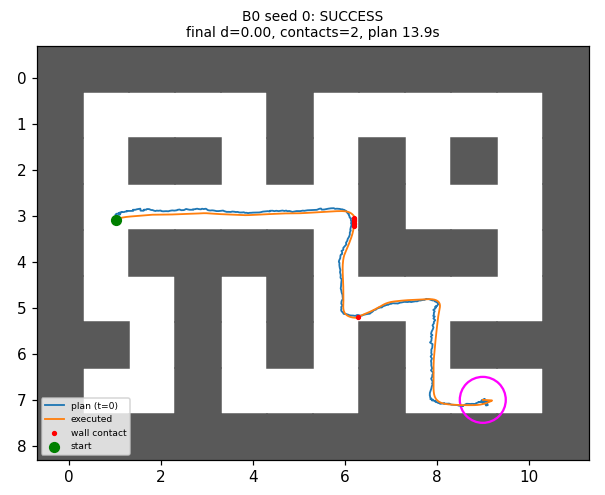

seed 1
  start_cell             Sirius=3,3                    Colab=3,3
  success                Sirius=False                  Colab=False
  final_dist_to_goal     Sirius=1.8015140814394315     Colab=1.801514081461394
  first_success_step     Sirius=None                   Colab=None
  wall_contact_events    Sirius=2                      Colab=2
  planning_time_s        Sirius=2.190562714000002      Colab=13.84359887699975


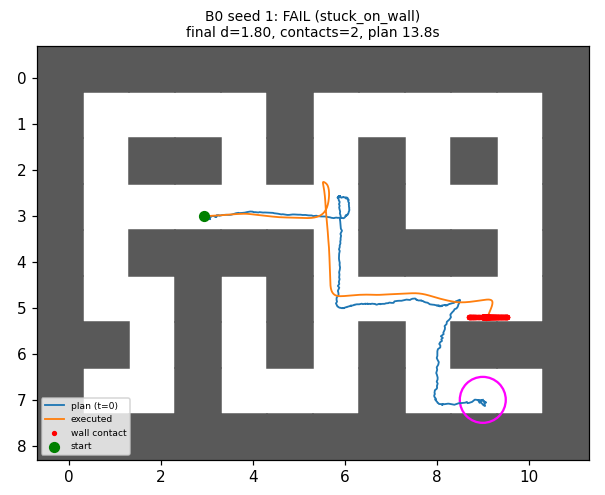

In [ ]:
import json
from IPython.display import Image, display
keys = ['start_cell', 'success', 'final_dist_to_goal', 'first_success_step', 'wall_contact_events', 'planning_time_s']
for s in (0, 1):
    a = json.load(open(f'{REPO_DIR}/{B0}/results/smoke/episodes/seed{s:03d}.json'))
    b = json.load(open(f'{REPO_DIR}/{B0}/results/smoke_colab/episodes/seed{s:03d}.json'))
    print(f'seed {s}')
    for k in keys:
        print(f'  {k:22s} Sirius={a.get(k)!s:22s} Colab={b.get(k)}')
    display(Image(f'{REPO_DIR}/{B0}/results/smoke_colab/episodes/seed{s:03d}.png', width=380))

## C2. 用假模型測整條流程

`--fake` 用假的環境和假的 Diffuser，幾秒鐘跑完，只用來確認程式沒寫錯。**這裡的成功率沒有意義。**

In [11]:
%cd {REPO_DIR}
!$PY experiments/common/test_common.py
!$PY experiments/blocked/make_scenarios.py --config experiments/blocked/configs/scenarios.json --fake --out /content/fake/scen.json | tail -n 2
!$PY experiments/blocked/run_blocked.py --config experiments/blocked/configs/smoke.json --fake --scenarios /content/fake/scen.json --out /content/fake/run --no_png
!$PY experiments/blocked/analyze_blocked.py /content/fake/run

/content/diffuser-project
ok   test_astar_matches_bfs
ok   test_blocked_route_and_waypoints
ok   test_fake_episodes
ok   test_maze_layout
ok   test_obstacle_geometry
ok   test_plan_collision_check
ok   test_segment_horizon
ok   test_wall_depth
ALL 8 TESTS PASSED
[scen] seed  80: obstacle (5, 7) at t=222 (B0 enters at 280), detour 16 cells (+8), 1 waypoint(s)
[scen] 100 scenarios -> ../fake/scen.json | skipped {'no_valid_cell': 31}
[B0] full_s004        success=False obstacle_collision   steps=204 replans=0 plans=  1 astar=0 plan_time=0.0s
[B0] full_s005        success=False obstacle_collision   steps=265 replans=0 plans=  1 astar=0 plan_time=0.0s
[B0] full_s006        success=False obstacle_collision   steps=202 replans=0 plans=  1 astar=0 plan_time=0.0s
[B0] done in 0.7s -> ../fake/run/B0
[B1] full_s004        success=True                       steps=747 replans=7 plans=113 astar=0 plan_time=0.0s
[B1] full_s005        success=True                       steps=723 replans=7 plans=113 as

## C3. 產生情境清單（⚠️ 不要重跑）

從 seed 0 開始，挑出「障礙物擋在 B0 實際會走的走廊上、有別條路、時間來得及」的情境。
**結果**：50 個完全堵塞＋50 個部分堵塞（同樣位置，只擋半條走廊）。繞路比原路多 4–12 格，障礙物在 t = 50–205 出現。障礙物集中在 (4,6)、(5,7)、(5,9) 幾格，因為終點固定，其他走廊大多一堵就無路可走（報告要寫成限制）。
已備份到 Drive 的 `results/scenarios_v1.json`；重跑會產生不同的清單，所有結果就對不上了。

/content/diffuser-project

[scen] seed   0: skip (no_valid_cell)
[scen] seed   1: obstacle (4, 6) at t=97 (B0 enters at 195), detour 15 cells (+8), 1 waypoint(s)
[scen] seed   2: skip (no_valid_cell)
[scen] seed   3: obstacle (5, 9) at t=131 (B0 enters at 247), detour 17 cells (+12), 1 waypoint(s)
[scen] seed   4: obstacle (4, 6) at t=135 (B0 enters at 171), detour 15 cells (+8), 1 waypoint(s)
[scen] seed   5: skip (b0_fails_without_obstacle)
[scen] seed   6: obstacle (5, 7) at t=140 (B0 enters at 251), detour 18 cells (+12), 1 waypoint(s)
[scen] seed   7: skip (no_valid_cell)
[scen] seed   8: skip (b0_fails_without_obstacle)
[scen] seed   9: skip (no_valid_cell)
[scen] seed  10: skip (b0_fails_without_obstacle)
[scen] seed  11: obstacle (5, 7) at t=127 (B0 enters at 255), detour 16 cells (+10), 1 waypoint(s)
[scen] seed  12: obstacle (4, 6) at t=152 (B0 enters at 185), detour 15 cells (+8), 1 waypoint(s)
[scen] seed  13: skip (no_valid_cell)
[scen] seed  14: obstacle (4, 6) at t=92 (B

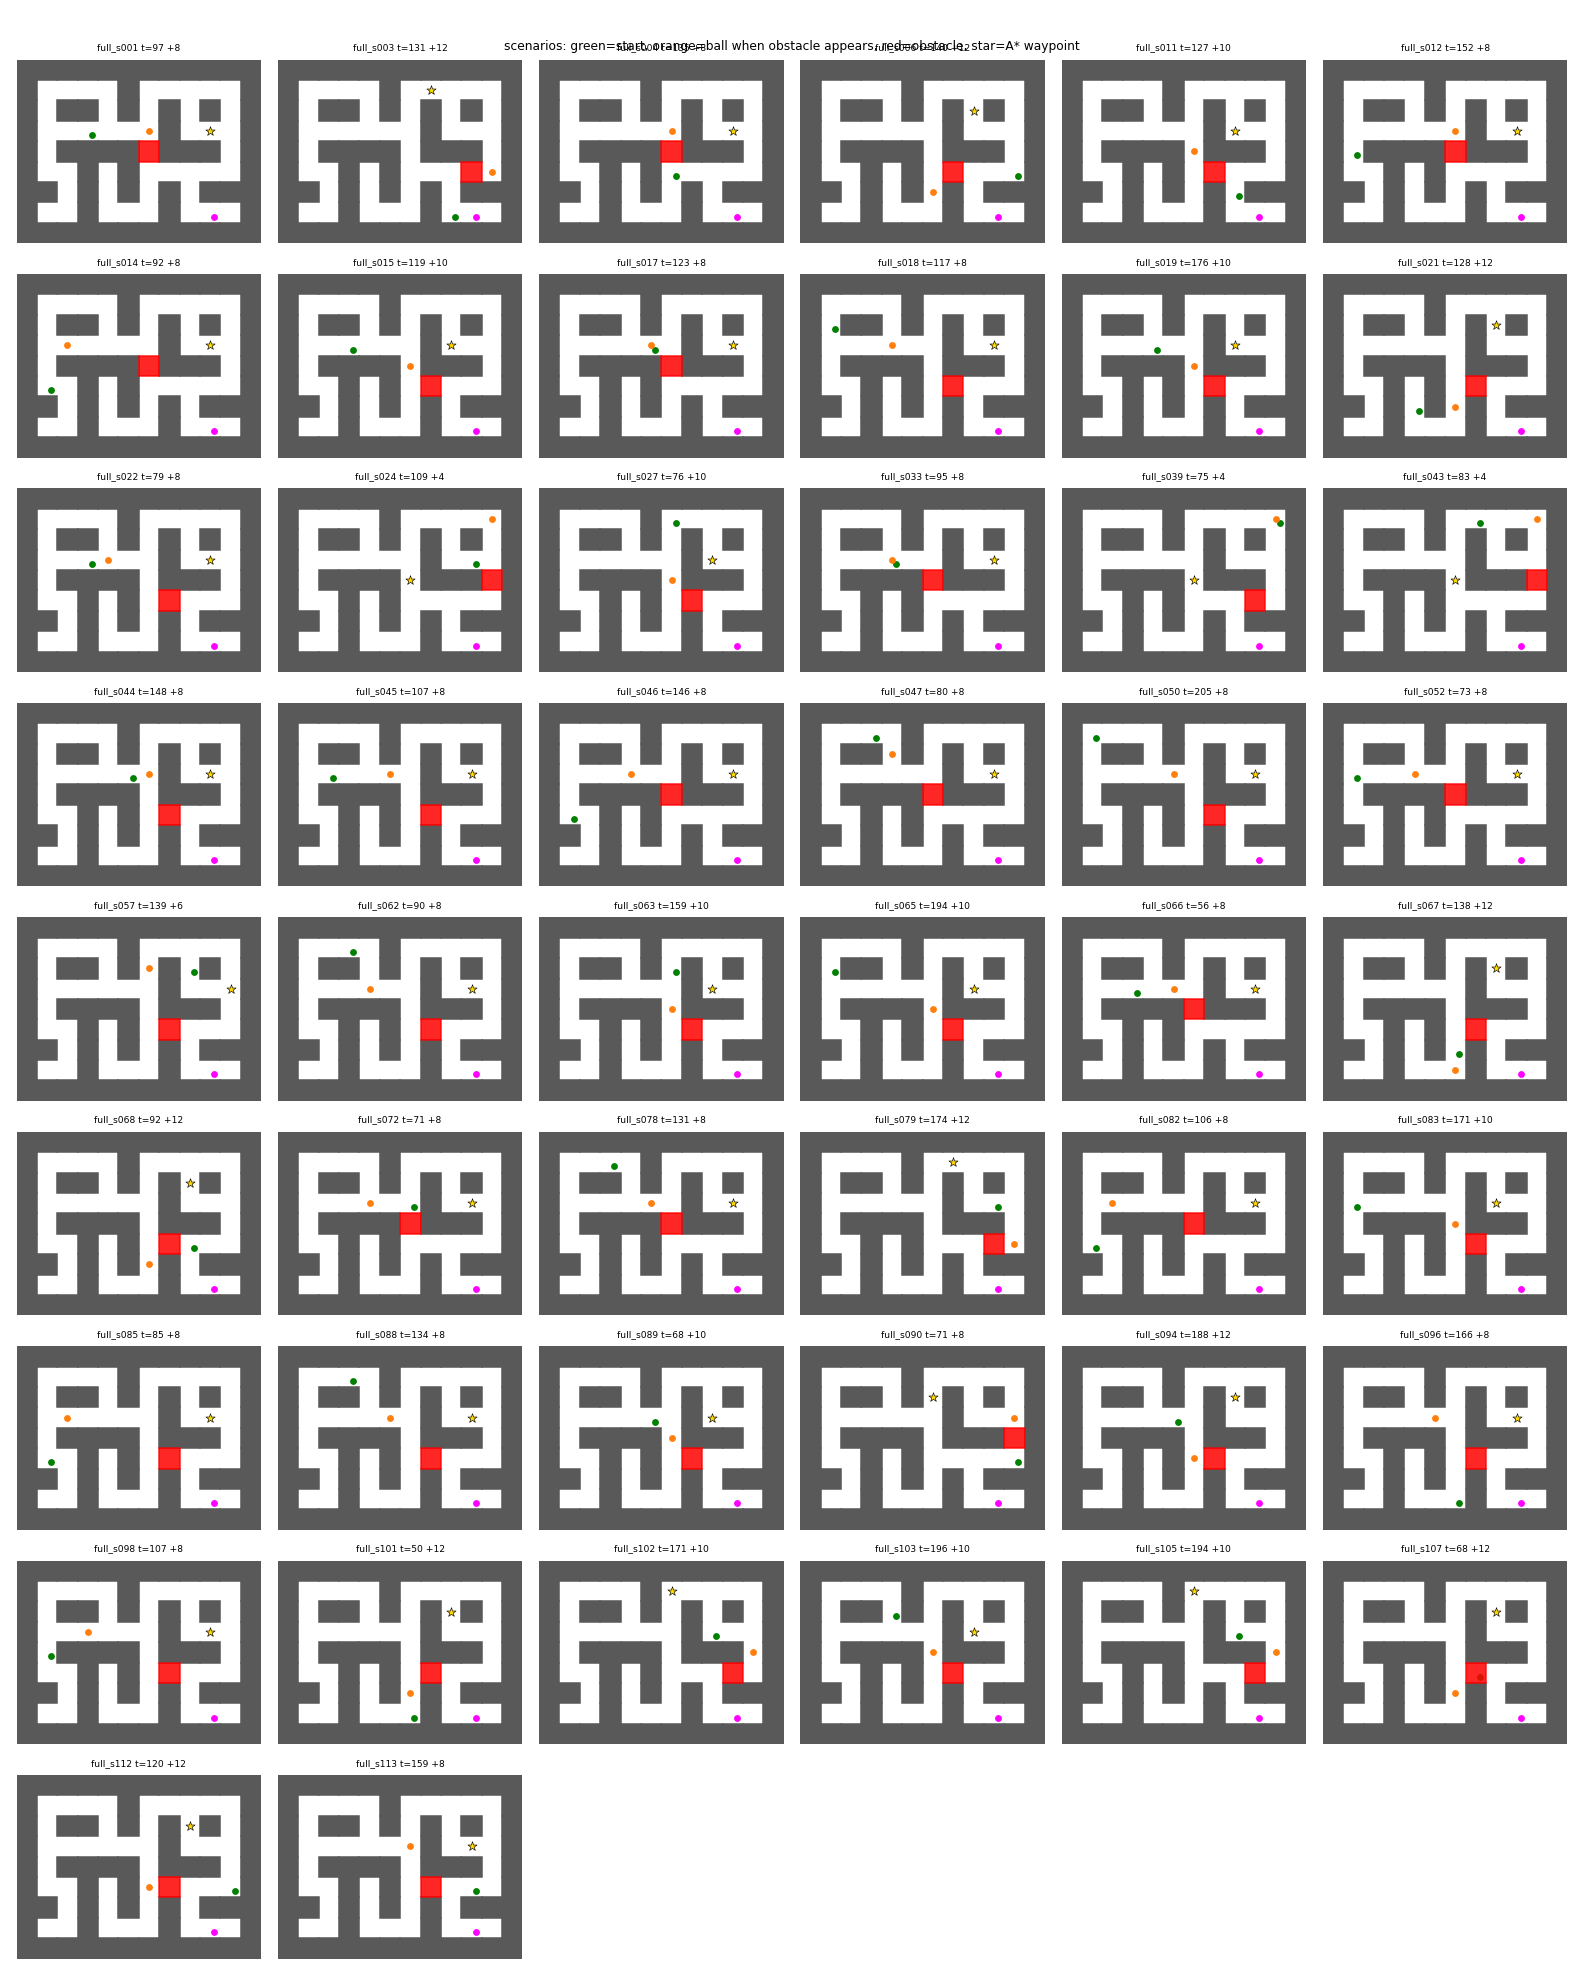

In [ ]:
%cd {REPO_DIR}
!$PY experiments/blocked/make_scenarios.py --config {cfg('experiments/blocked/configs/scenarios.json')}
!cp experiments/blocked/scenarios/scenarios_v1.* {RESULTS}/   # 備份到 Drive
show(f'{REPO_DIR}/experiments/blocked/scenarios/scenarios_v1.png', 1100)

In [ ]:
from google.colab import files
files.download(f'{REPO_DIR}/experiments/blocked/scenarios/scenarios_v1.json')
files.download(f'{REPO_DIR}/experiments/blocked/scenarios/scenarios_v1.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## C4. B2 小實驗（風險 R2）

在 B2 第一次檢查的時間點，抽 16 條計畫，數有幾條能自己繞到另一條走廊（不撞障礙物、不穿牆）。
**結果**：只有 20–30% 的情境抽得到（`full` 4/20、`deadline` 6/20）→ R2 沒有發生，A* 換走廊有必要。T4 上一次抽 1、4、16 條都約 3.7 秒，所以全部方法都用 N = 16。

In [ ]:
%cd {REPO_DIR}
!$PY experiments/blocked/probe_b2.py --config {cfg('experiments/blocked/configs/probe_b2.json')} --out {RESULTS}/probe_b2

/content/diffuser-project

[probe] full_s001      t*=100 full(H=384): valid 1/16 clear 1 3.7s | deadline(H=384): valid 0/16 clear 0 3.4s | euclid(H=264): valid 0/16 clear 0 3.5s
[probe] full_s003      t*=140 full(H=384): valid 0/16 clear 0 4.1s | deadline(H=384): valid 0/16 clear 0 3.5s | euclid(H=152): valid 0/16 clear 1 3.5s
[probe] full_s004      t*=140 full(H=384): valid 0/16 clear 1 3.9s | deadline(H=384): valid 1/16 clear 1 3.4s | euclid(H=276): valid 0/16 clear 0 3.4s
[probe] full_s006      t*=140 full(H=384): valid 0/16 clear 0 3.4s | deadline(H=384): valid 0/16 clear 0 3.4s | euclid(H=192): valid 0/16 clear 3 4.0s
[probe] full_s011      t*=130 full(H=384): valid 0/16 clear 0 3.3s | deadline(H=384): valid 1/16 clear 1 3.3s | euclid(H=228): valid 0/16 clear 0 4.6s
[probe] full_s012      t*=160 full(H=384): valid 0/16 clear 0 3.3s | deadline(H=384): valid 1/16 clear 1 4.1s | euclid(H=272): valid 0/16 clear 0 3.8s
[probe] full_s014      t*=100 full(H=384): valid 0/16 clear 0 3.4s 

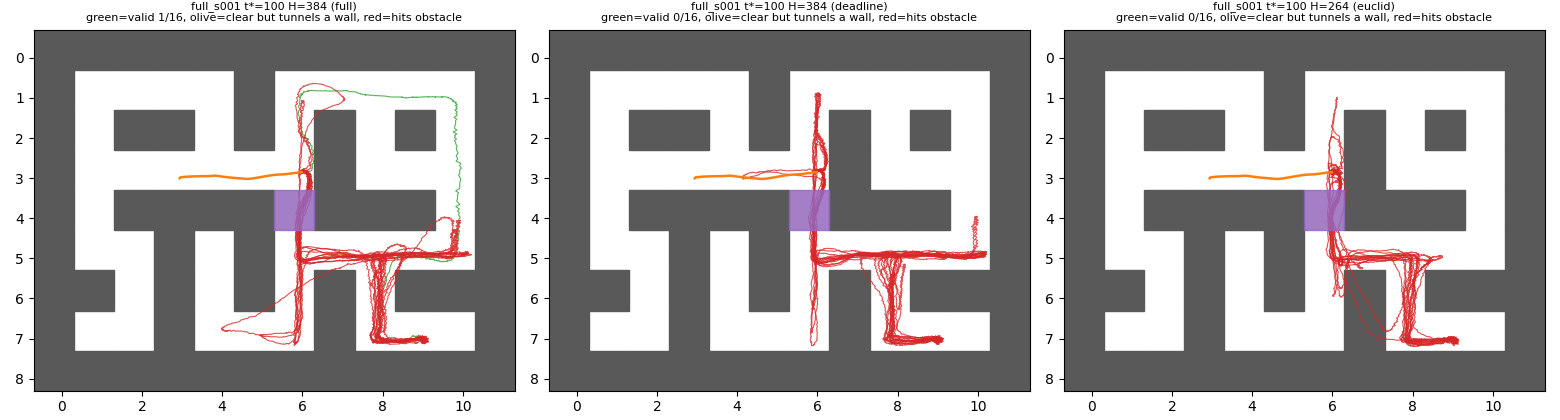

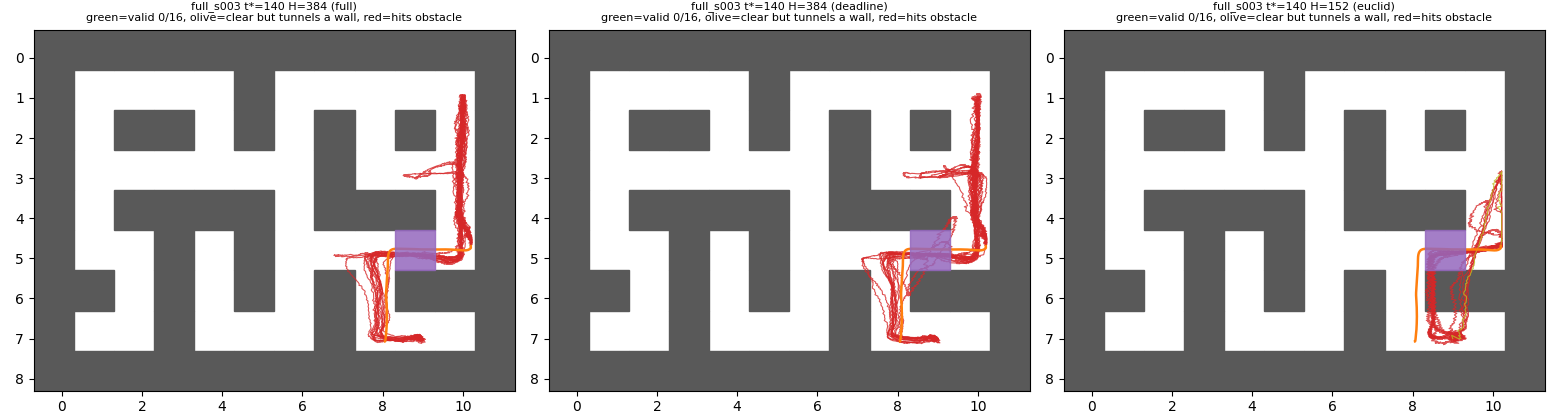

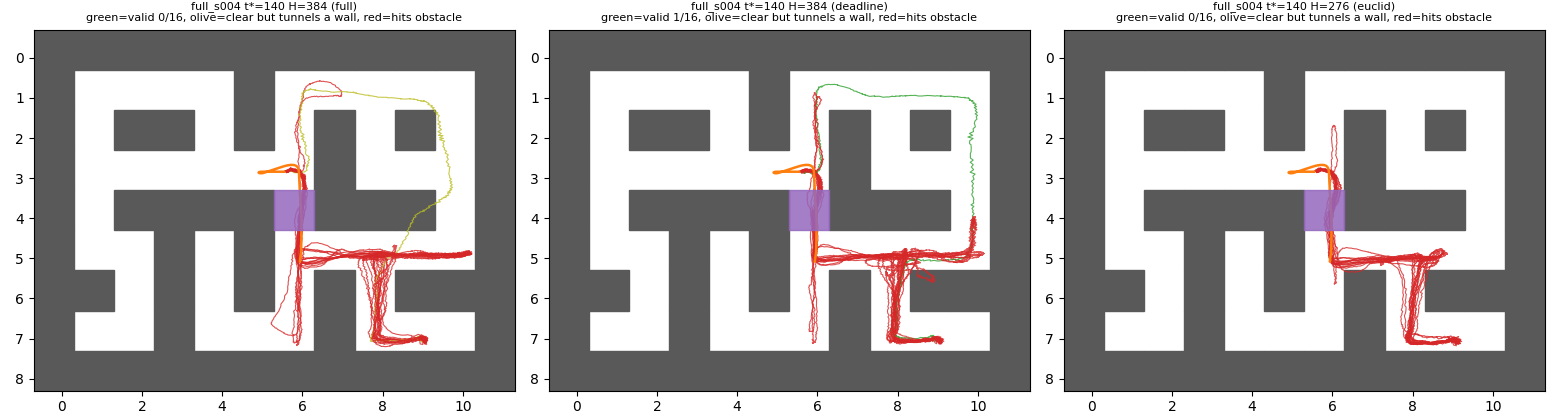

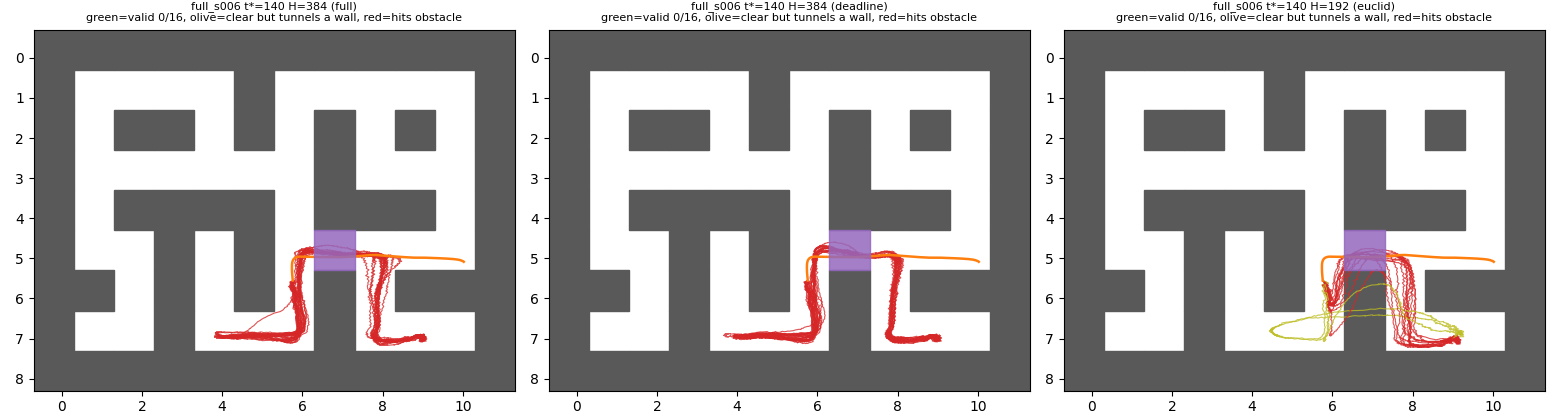

In [ ]:
import glob
for p in sorted(glob.glob(f'{RESULTS}/probe_b2/scenarios/*.png'))[:4]:
    show(p)

## C5. 四種方法 smoke test（3 個情境）

正式比較前的檢查。這一輪用的是最終設定（replan 長度 `deadline`、N = 16、不接受穿牆的計畫）。
**結果**：B0 0/3、B1 3/3、B2 2/3、Ours 3/3，行為都符合設計。

/content/diffuser-project

[B0] done in 0.0s -> ../drive/MyDrive/ece780_diffuser_cache/results/smoke/B0
[B1] done in 0.0s -> ../drive/MyDrive/ece780_diffuser_cache/results/smoke/B1
[B2] done in 0.0s -> ../drive/MyDrive/ece780_diffuser_cache/results/smoke/B2
[Ours] done in 0.0s -> ../drive/MyDrive/ece780_diffuser_cache/results/smoke/Ours
method   n  success        95% CI  collide  plans  plan s  failures
B0       3       0%     0%-  56%     100%    1.0     3.7  {'obstacle_collision': 3}
B1       3     100%    44%- 100%       0%  113.0    30.8  {}
B2       3      67%    21%-  94%       0%   70.3    20.0  {'stuck_on_wall': 1}
Ours     3     100%    44%- 100%       0%   43.7    14.2  {}
Ours vs B2 (paired): {'both': 2, 'only_ours': 1, 'only_b2': 0, 'neither': 0}


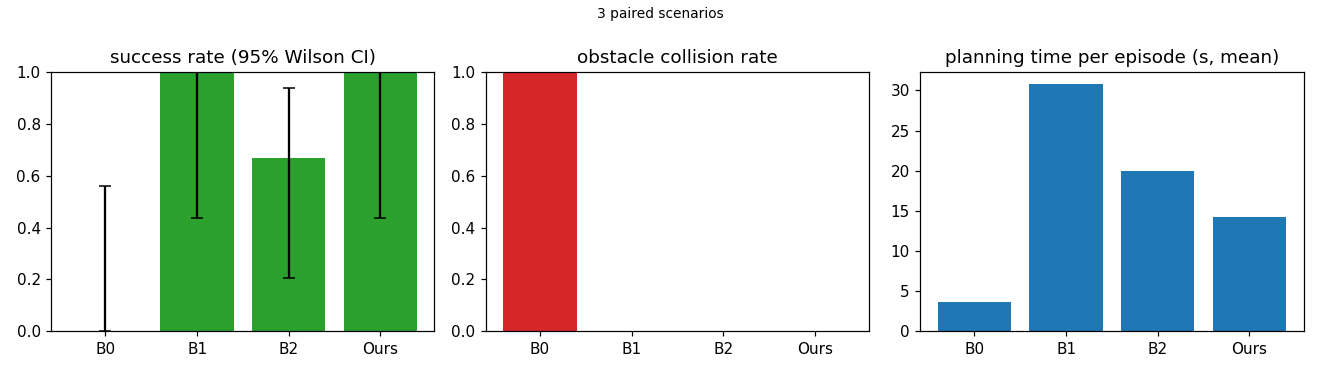

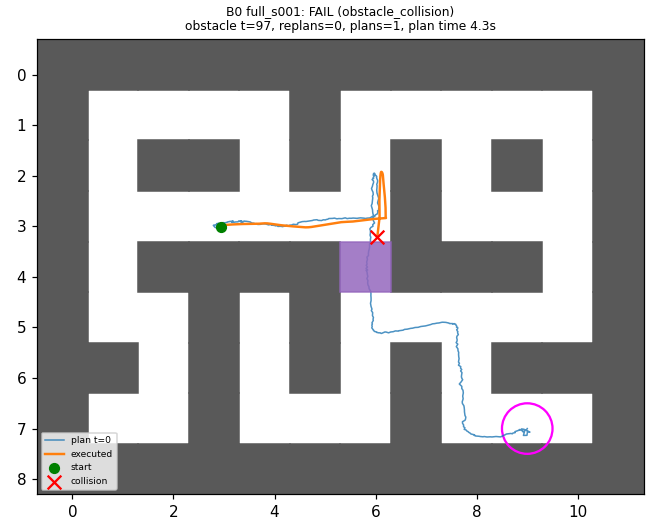

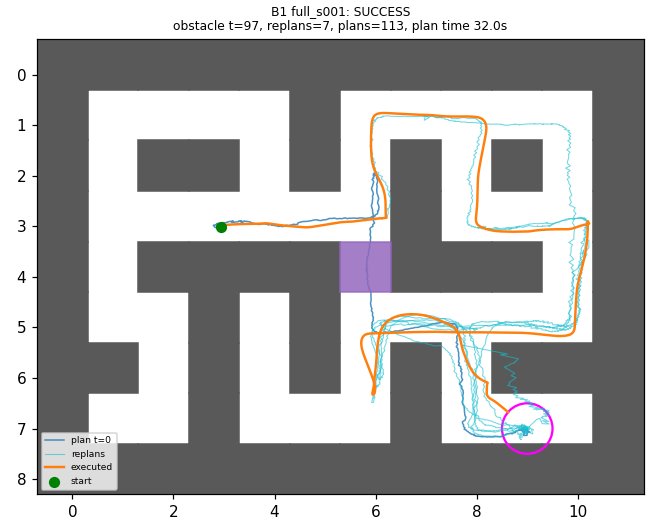

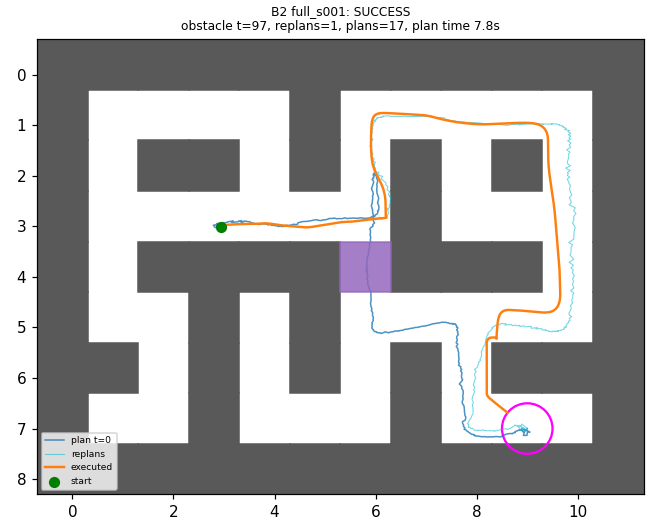

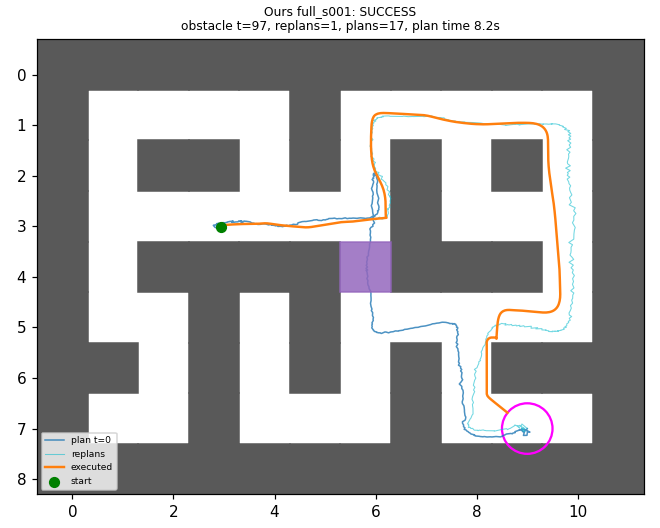

In [ ]:
%cd {REPO_DIR}
!$PY experiments/blocked/run_blocked.py --config {cfg('experiments/blocked/configs/smoke.json')} --out {RESULTS}/smoke
!$PY experiments/blocked/analyze_blocked.py {RESULTS}/smoke
show(f'{RESULTS}/smoke/overview.png')
for m in ['B0', 'B1', 'B2', 'Ours']:
    for p in sorted(glob.glob(f'{RESULTS}/smoke/{m}/episodes/*.png'))[:1]:
        show(p, 450)

In [ ]:
import json, glob
for f in sorted(glob.glob(f'{RESULTS}/smoke/Ours/episodes/*.json')):
    r = json.load(open(f))
    print(r['scenario_id'], 'success' if r['success'] else 'FAIL ' + r['failure_reason'],
          '| collision_step', r['collision_step'])
    if not r['success']:
        for e in r['events']:
            print('    ', e)
        show(f[:-5] + '.png', 600)

full_s001 success | collision_step None
full_s003 success | collision_step None
full_s004 success | collision_step None


## C6. 正式比較：完全堵塞（主結果）

50 個情境 × B0、B1、B2、Ours（約 1.5–2 小時），之後補 Oracle（幾分鐘）。
Oracle 在障礙物出現前跟大家一樣照 Diffuser 的第一條計畫走，出現後改用已知地圖 A*＋PD 控制器，代表「同樣狀況下最好能做到多少」。

**結果**：B0 0%、B1 34%、B2 20%、**Ours 76%**、Oracle 100%。Ours 撞障礙物 0 次，抽樣量只有 B2 的 28%。配對比較：只有 Ours 成功 28、只有 B2 成功 0。

/content/diffuser-project

[B0] done in 0.0s -> ../drive/MyDrive/ece780_diffuser_cache/results/main/B0
[B1] done in 0.0s -> ../drive/MyDrive/ece780_diffuser_cache/results/main/B1
[B2] done in 0.0s -> ../drive/MyDrive/ece780_diffuser_cache/results/main/B2
[Ours] done in 0.0s -> ../drive/MyDrive/ece780_diffuser_cache/results/main/Ours
method   n  success        95% CI  collide  plans  plan s  failures
B0      50       0%     0%-   7%     100%    1.0     3.7  {'obstacle_collision': 50}
B1      50      34%    22%-  48%      34%  100.5    26.1  {'timeout_still_moving': 16, 'obstacle_collision': 17}
B2      50      20%    11%-  33%      12%  194.3    46.2  {'stuck_on_wall': 22, 'timeout_still_moving': 12, 'obstacle_collision': 6}
Ours    50      76%    63%-  86%       0%   53.8    15.4  {'timeout_still_moving': 9, 'stuck_on_wall': 3}
Ours vs B2 (paired): {'both': 10, 'only_ours': 28, 'only_b2': 0, 'neither': 12}


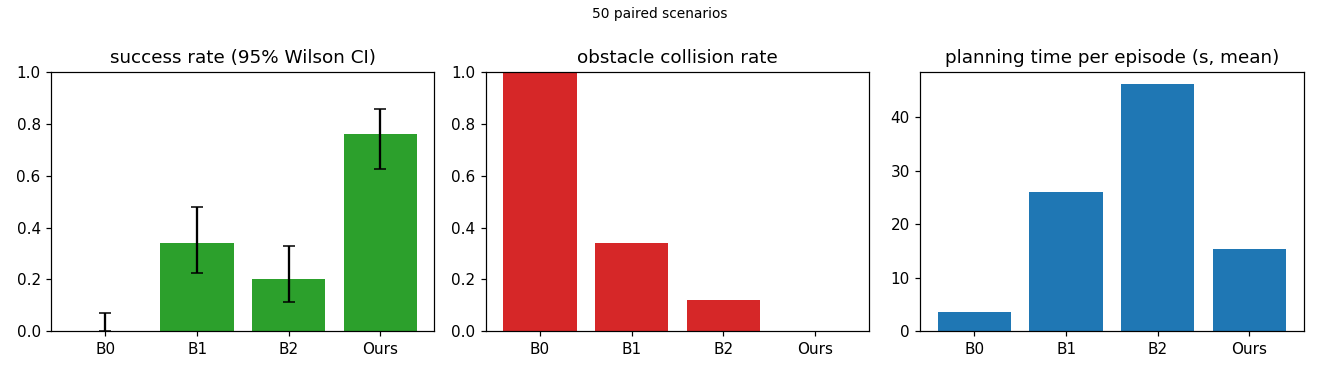

In [19]:
%cd {REPO_DIR}
!$PY experiments/blocked/run_blocked.py --config {cfg('experiments/blocked/configs/main.json')} --out {RESULTS}/main --methods B0 B1 B2 Ours
!$PY experiments/blocked/analyze_blocked.py {RESULTS}/main
show(f'{RESULTS}/main/overview.png')

/content/diffuser-project

[Oracle] full_s001        success=True                       steps=454 replans=1 plans=  1 astar=1 plan_time=3.5s
[Oracle] full_s003        success=True                       steps=516 replans=1 plans=  1 astar=1 plan_time=3.3s
[Oracle] full_s004        success=True                       steps=490 replans=1 plans=  1 astar=1 plan_time=4.0s
[Oracle] full_s006        success=True                       steps=574 replans=1 plans=  1 astar=1 plan_time=3.7s
[Oracle] full_s011        success=True                       steps=499 replans=1 plans=  1 astar=1 plan_time=3.3s
[Oracle] full_s012        success=True                       steps=509 replans=1 plans=  1 astar=1 plan_time=3.4s
[Oracle] full_s014        success=True                       steps=523 replans=1 plans=  1 astar=1 plan_time=4.2s
[Oracle] full_s015        success=True                       steps=511 replans=1 plans=  1 astar=1 plan_time=3.3s
[Oracle] full_s017        success=True                       

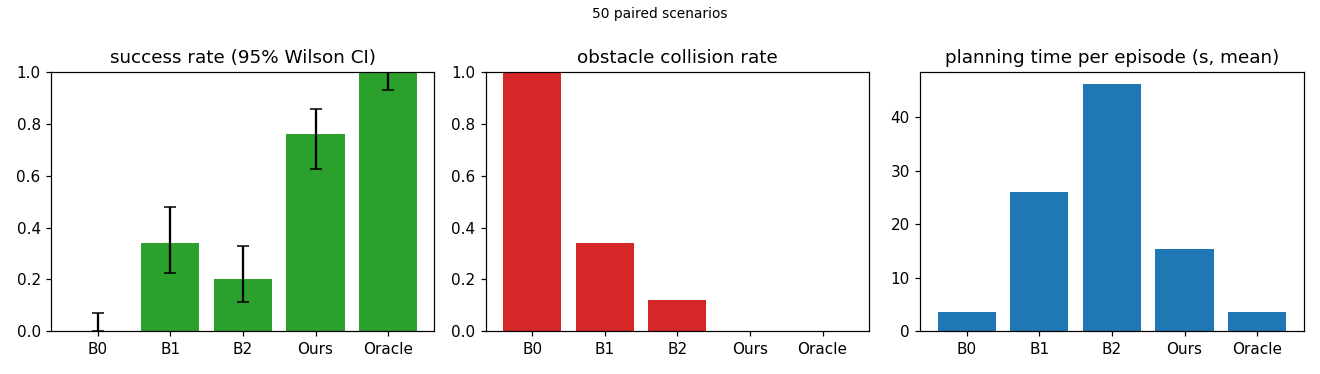

In [20]:
%cd {REPO_DIR}
!$PY experiments/blocked/run_blocked.py --config {cfg('experiments/blocked/configs/main.json')} --out {RESULTS}/main --methods Oracle
!$PY experiments/blocked/analyze_blocked.py {RESULTS}/main
show(f'{RESULTS}/main/overview.png')

## C7. 失敗分析（完全堵塞）

**Ours 的 12 個失敗**都有換到另一條走廊、都沒撞障礙物：
- 5 個在終點前卡在 (6,9) 那面牆（`final_d` = 1.8）：Diffuser 本身的問題，沒有障礙物時 B0 也會這樣（B0 README F2）
- 3 個過了 waypoint (3,9) 後卡牆（`final_d` = 3.8）
- 4 個繞路太長、時間不夠（其中 full_s006 只差 0.01）

**B2 的 40 個失敗**裡有 16 個是同樣卡在 (6,9) 牆前；扣掉之後 B2 還有 24 個、Ours 只有 7 個，結論不變。
簡報對照圖用 **full_s004**（不要用 full_s011，那張 B2 是卡在 (6,9)，屬於 Diffuser 本身的問題）。

B2   Counter({'stuck_on_wall': 22, 'timeout_still_moving': 12, 'obstacle_collision': 6})
Ours Counter({'timeout_still_moving': 9, 'stuck_on_wall': 3})

full_s006 timeout_still_moving | astar 1 | segments 2 | steps 800 | final_d 0.51 | min_d 0.51
full_s014 timeout_still_moving | astar 1 | segments 2 | steps 800 | final_d 3.8 | min_d 3.8
full_s022 timeout_still_moving | astar 1 | segments 2 | steps 800 | final_d 3.8 | min_d 3.8
full_s045 timeout_still_moving | astar 1 | segments 3 | steps 800 | final_d 1.81 | min_d 1.8
full_s052 timeout_still_moving | astar 1 | segments 2 | steps 800 | final_d 1.81 | min_d 1.8
full_s065 timeout_still_moving | astar 2 | segments 4 | steps 800 | final_d 1.32 | min_d 1.32
full_s066 stuck_on_wall | astar 1 | segments 2 | steps 800 | final_d 1.8 | min_d 1.8
full_s068 timeout_still_moving | astar 2 | segments 6 | steps 800 | final_d 2.13 | min_d 1.88
full_s078 stuck_on_wall | astar 0 | segments 0 | steps 800 | final_d 1.8 | min_d 1.8
full_s088 timeout_still_mo

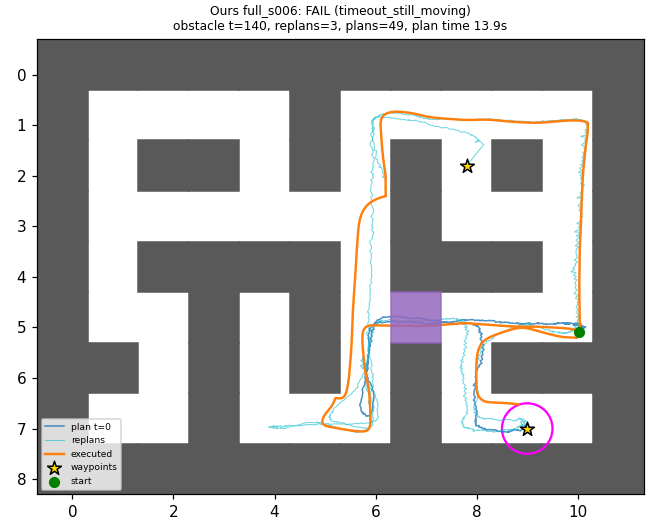

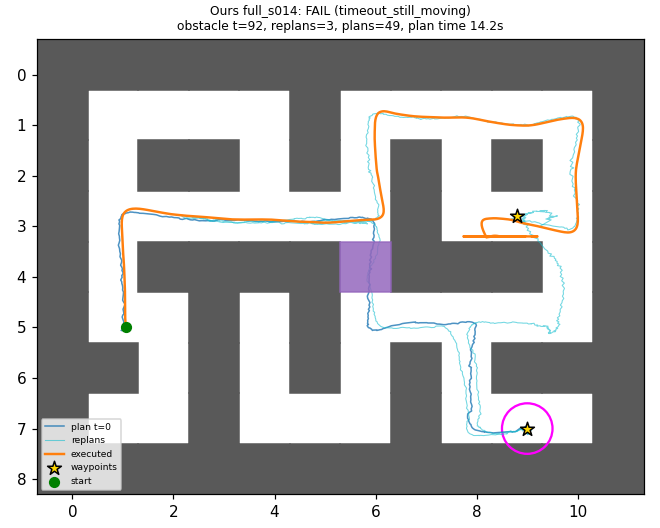

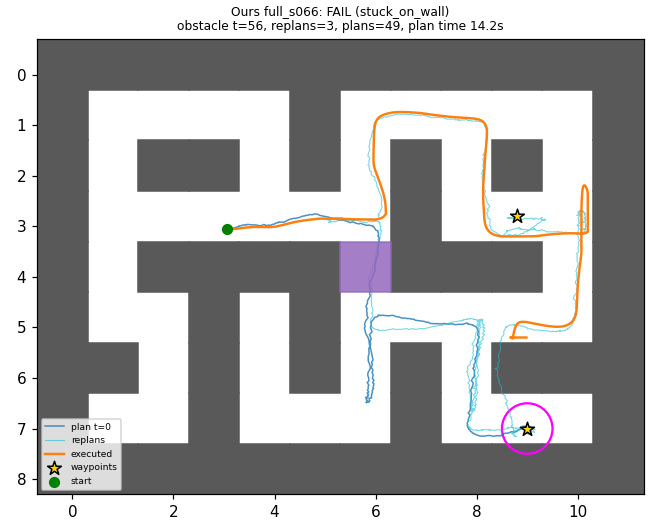


=== 只有 Ours 成功： ['full_s004', 'full_s011']
full_s004 | B2: stuck_on_wall


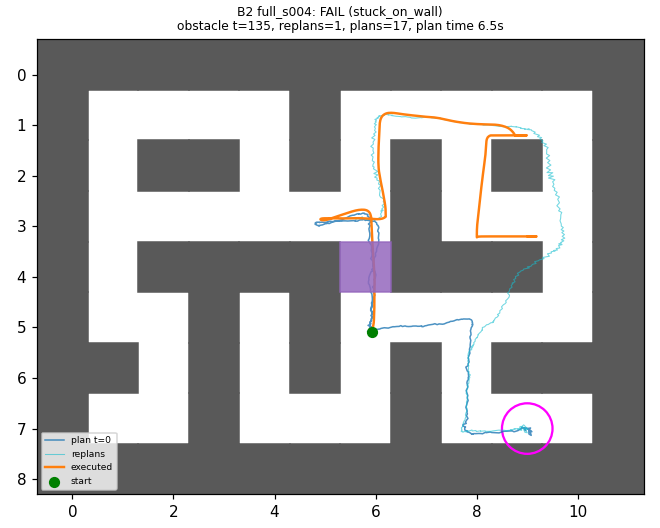

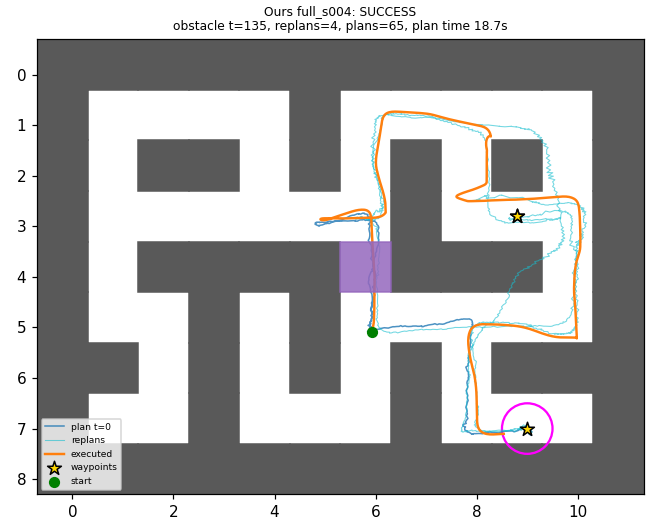

full_s011 | B2: stuck_on_wall


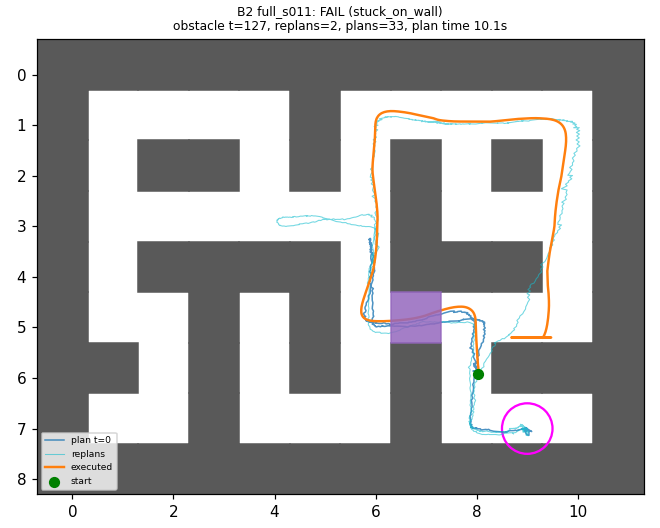

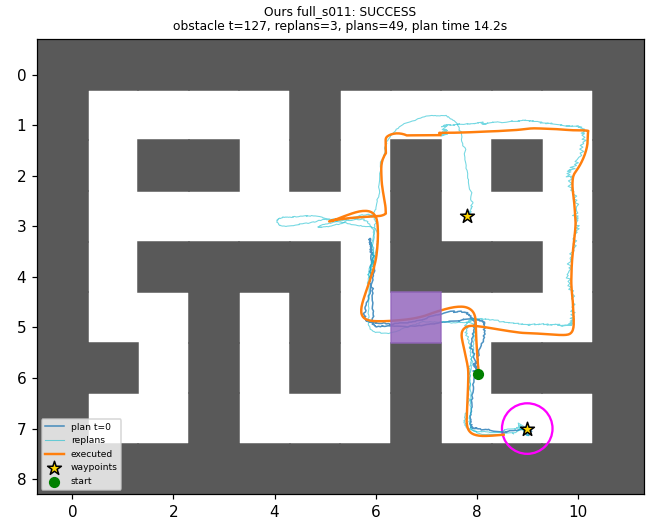

In [ ]:
import json, glob, collections
from IPython.display import Image, display

def load(m):
    return {json.load(open(f))['scenario_id']: json.load(open(f))
            for f in sorted(glob.glob(f'{RESULTS}/main/{m}/episodes/*.json'))}
B2, OURS = load('B2'), load('Ours')

# 1. 失敗原因分類 + Ours 失敗回合清單
print('B2  ', collections.Counter(r['failure_reason'] for r in B2.values() if not r['success']))
print('Ours', collections.Counter(r['failure_reason'] for r in OURS.values() if not r['success']))
print()
for sid, r in OURS.items():
    if not r['success']:
        print(sid, r['failure_reason'], '| astar', r['n_astar'], '| segments', r['n_segments'],
              '| steps', r['steps'], '| final_d', round(r['final_dist_to_goal'], 2),
              '| min_d', round(r['min_dist_to_goal'], 2))

def png(m, sid):
    return f'{RESULTS}/main/{m}/episodes/{sid}.png'

# 2. Ours 超時 2 張、卡牆 1 張
timeout = [s for s, r in OURS.items() if r['failure_reason'] == 'timeout_still_moving'][:2]
stuck = [s for s, r in OURS.items() if r['failure_reason'] == 'stuck_on_wall'][:1]
print('\n=== Ours 失敗：', timeout + stuck)
for s in timeout + stuck:
    display(Image(png('Ours', s), width=450))

# 3. 只有 Ours 成功：B2 和 Ours 並排（優先挑 B2 卡牆的）
only = [s for s in OURS if OURS[s]['success'] and not B2[s]['success']]
only.sort(key=lambda s: B2[s]['failure_reason'] != 'stuck_on_wall')
print('\n=== 只有 Ours 成功：', only[:2])
for s in only[:2]:
    print(s, '| B2:', B2[s]['failure_reason'])
    display(Image(png('B2', s), width=450))
    display(Image(png('Ours', s), width=450))

In [ ]:
for m, D in [('B2', B2), ('Ours', OURS)]:
    f = [r for r in D.values() if not r['success']]
    near69 = sum(abs(r['final_dist_to_goal'] - 1.8) < 0.1 for r in f)
    print(m, '失敗', len(f), '| 其中卡在 (6,9) 牆前（A 類）', near69)

B2 失敗 40 | 其中卡在 (6,9) 牆前（A 類） 16
Ours 失敗 12 | 其中卡在 (6,9) 牆前（A 類） 5


## C8. 部分堵塞

同樣 50 個位置，但障礙物只擋住半條走廊（留 0.5 寬的空隙，球直徑 0.2）。測方法的另一半：best-of-N 處理部分堵塞。
**結果**：B0 46%、B1 40%、B2 36%、**Ours 70%**、Oracle 100%；配對比較只有 Ours 成功 18、只有 B2 成功 1。
- 半條走廊常常擠得過去，所以 B0 就有 46%
- 只靠 Diffuser 重新規劃（B1、B2）反而比不 replan 還差：新計畫常繞遠路、超時或卡牆
- 預測觸發偏保守，會誤報（例如 partial50_s004：B0 成功，B2 和 Ours 都換了更差的路而失敗）
- 只有加了地圖的 Ours 明顯超過 B0

/content/diffuser-project

[B0] partial50_s006   success=False obstacle_collision   steps=249 replans=0 plans=  1 astar=0 plan_time=3.9s
[B0] partial50_s011   success=True                       steps=367 replans=0 plans=  1 astar=0 plan_time=3.7s
[B0] partial50_s012   success=True                       steps=363 replans=0 plans=  1 astar=0 plan_time=3.4s
[B0] partial50_s014   success=True                       steps=364 replans=0 plans=  1 astar=0 plan_time=3.3s
[B0] partial50_s015   success=False obstacle_collision   steps=248 replans=0 plans=  1 astar=0 plan_time=4.5s
[B0] partial50_s017   success=True                       steps=357 replans=0 plans=  1 astar=0 plan_time=3.4s
[B0] partial50_s018   success=False obstacle_collision   steps=238 replans=0 plans=  1 astar=0 plan_time=3.3s
[B0] partial50_s019   success=False obstacle_collision   steps=226 replans=0 plans=  1 astar=0 plan_time=3.7s
[B0] partial50_s021   success=False obstacle_collision   steps=159 replans=0 plans=  1 astar=

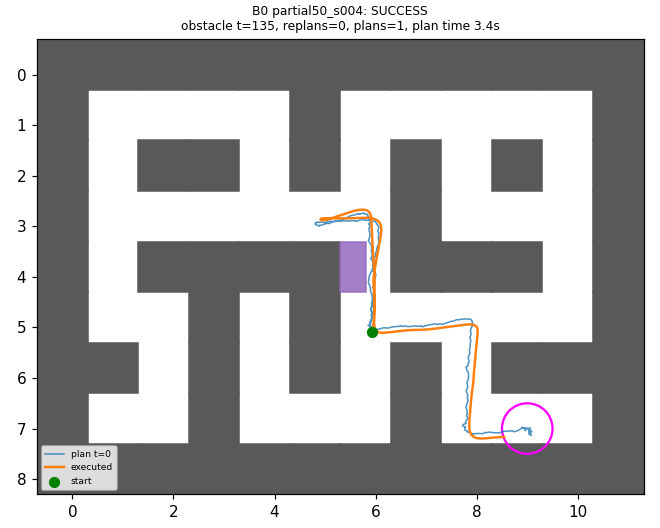

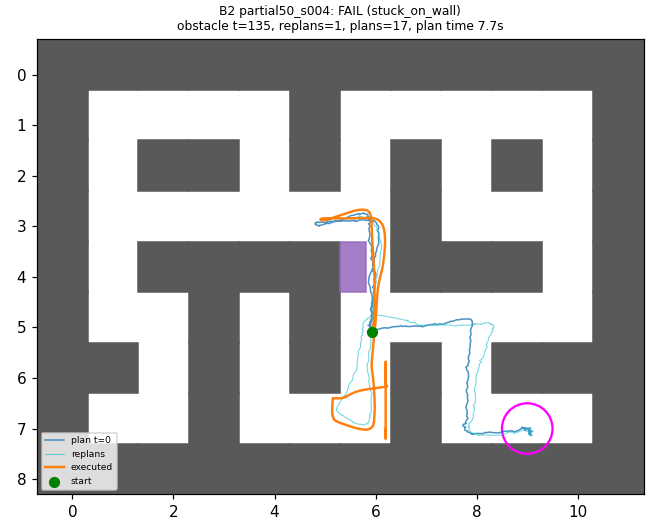

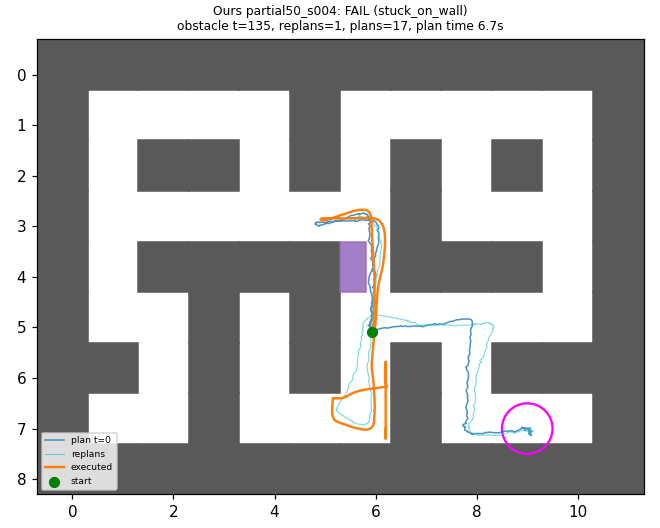

In [23]:
import json
c = json.load(open(f'{REPO_DIR}/experiments/blocked/configs/main.json'))
c['name'] = 'blocked_partial'
c['kinds'] = ['partial']
c['device'] = DEVICE
json.dump(c, open('/content/partial.json', 'w'), indent=2)

%cd {REPO_DIR}
!$PY experiments/blocked/run_blocked.py --config /content/partial.json --out {RESULTS}/partial --methods B0 B2 Ours Oracle
!$PY experiments/blocked/analyze_blocked.py {RESULTS}/partial
for m in ['B0', 'B2', 'Ours']:
    show(f'{RESULTS}/partial/{m}/episodes/partial50_s004.png', 450)

In [24]:
%cd {REPO_DIR}
!$PY experiments/blocked/run_blocked.py --config /content/partial.json --out {RESULTS}/partial --methods B1
!$PY experiments/blocked/analyze_blocked.py {RESULTS}/partial

/content/diffuser-project

[B1] partial50_s001   success=True                       steps=795 replans=7 plans=113 astar=0 plan_time=28.7s
[B1] partial50_s003   success=True                       steps=745 replans=7 plans=113 astar=0 plan_time=29.6s
[B1] partial50_s004   success=False timeout_still_moving steps=800 replans=7 plans=113 astar=0 plan_time=28.8s
[B1] partial50_s006   success=False timeout_still_moving steps=800 replans=7 plans=113 astar=0 plan_time=28.5s
[B1] partial50_s011   success=False timeout_still_moving steps=800 replans=7 plans=113 astar=0 plan_time=29.0s
[B1] partial50_s012   success=False timeout_still_moving steps=800 replans=7 plans=113 astar=0 plan_time=29.1s
[B1] partial50_s014   success=False obstacle_collision   steps=653 replans=6 plans= 97 astar=0 plan_time=25.2s
[B1] partial50_s015   success=False obstacle_collision   steps=168 replans=1 plans= 17 astar=0 plan_time=6.7s
[B1] partial50_s017   success=True                       steps=742 replans=7 plans=113

## C9. 消融一：waypoint 怎麼挑（greedy vs 每個路口）

`junctions`：A* 路線上每個路口都設 waypoint（proposal 原本的寫法）；主結果用的是 `greedy`（只挑必要的，通常 1 個）。只跑 Ours。
**結果**：junctions 62%（碰撞 30%）vs greedy 76%（碰撞 0%），抽樣量 107 vs 54。15 次碰撞**全部**發生在緊鄰障礙物的路口 waypoint（幾乎都是 (5,8)）：球在那裡換段轉彎時衝過頭，擦到障礙物。結論：waypoint 不是越多越好。

In [18]:
import json
c = json.load(open(f'{REPO_DIR}/experiments/blocked/configs/main.json'))
c['name'] = 'ablation_junctions'
c['method_params']['Ours']['waypoint_mode'] = 'junctions'
c['device'] = DEVICE
json.dump(c, open('/content/junctions.json', 'w'), indent=2)

%cd {REPO_DIR}
!$PY experiments/blocked/run_blocked.py --config /content/junctions.json --out {RESULTS}/ablation_junctions --methods Ours
!$PY experiments/blocked/analyze_blocked.py {RESULTS}/ablation_junctions

/content/diffuser-project

[Ours] full_s001        success=True                       steps=608 replans=1 plans= 17 astar=0 plan_time=8.1s
[Ours] full_s003        success=False obstacle_collision   steps=638 replans=11 plans=177 astar=3 plan_time=46.5s
[Ours] full_s004        success=True                       steps=614 replans=5 plans= 81 astar=1 plan_time=22.7s
[Ours] full_s006        success=True                       steps=758 replans=15 plans=241 astar=5 plan_time=63.2s
[Ours] full_s011        success=False obstacle_collision   steps=571 replans=6 plans= 97 astar=1 plan_time=26.0s
[Ours] full_s012        success=True                       steps=641 replans=5 plans= 81 astar=1 plan_time=21.8s
[Ours] full_s014        success=True                       steps=624 replans=7 plans=113 astar=1 plan_time=31.1s
[Ours] full_s015        success=False obstacle_collision   steps=580 replans=6 plans= 97 astar=1 plan_time=25.5s
[Ours] full_s017        success=True                       steps=624

In [21]:
for f in sorted(glob.glob(f'{RESULTS}/ablation_junctions/Ours/episodes/*.json')):
    r = json.load(open(f))
    if not r['obstacle_collision']:
        continue
    ob = r['obstacles'][0]['cell']
    wps = [w for e in r['events'] if e['event'] == 'astar' for w in e['waypoints'][:-1]]
    near = [w for w in wps if abs(w[0]-ob[0]) + abs(w[1]-ob[1]) == 1]
    print(r['scenario_id'], '| obstacle', ob, '| waypoints adjacent to obstacle', near)

full_s003 | obstacle [5, 9] | waypoints adjacent to obstacle [[5, 8]]
full_s011 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 8]]
full_s015 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 8]]
full_s019 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 8]]
full_s021 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 6], [5, 8], [5, 6], [5, 8], [5, 6], [5, 8], [5, 6], [5, 8], [5, 8], [5, 8]]
full_s022 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 8]]
full_s044 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 8]]
full_s045 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 8]]
full_s062 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 8]]
full_s079 | obstacle [5, 9] | waypoints adjacent to obstacle [[5, 8]]
full_s089 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 8], [5, 8]]
full_s101 | obstacle [5, 7] | waypoints adjacent to obstacle [[5, 6], [5, 8], [5, 8], [5, 8]]
full_s102 | obstacle [5, 9] | waypoints adjacent to obst

full_s003
    {'t': 140, 'event': 'astar', 'here': [5, 10], 'waypoints': [[3, 10], [1, 8], [3, 6], [5, 6], [5, 8], [7, 9]], 'route_len': 17}
    {'t': 140, 'event': 'segment', 'target': [3, 10], 'H': 92, 'n_cells': 2, 'n_clear': 16, 'n_ok': 16}
    {'t': 202, 'event': 'segment', 'target': [1, 8], 'H': 152, 'n_cells': 4, 'n_clear': 16, 'n_ok': 15}
    {'t': 373, 'event': 'segment', 'target': [3, 6], 'H': 152, 'n_cells': 4, 'n_clear': 15, 'n_ok': 12}
    {'t': 489, 'event': 'segment', 'target': [5, 6], 'H': 92, 'n_cells': 2, 'n_clear': 16, 'n_ok': 16}
    {'t': 545, 'event': 'segment', 'target': [5, 8], 'H': 92, 'n_cells': 2, 'n_clear': 2, 'n_ok': 2}
    {'t': 612, 'event': 'segment', 'target': [7, 9], 'H': 124, 'n_cells': 3, 'n_clear': 0, 'n_ok': 0}
    {'t': 620, 'event': 'segment', 'target': [7, 9], 'H': 124, 'n_cells': 3, 'n_clear': 0, 'n_ok': 0}
    {'t': 620, 'event': 'astar', 'here': [5, 8], 'waypoints': [[7, 9]], 'route_len': 3}
    {'t': 620, 'event': 'segment', 'target': [7, 9]

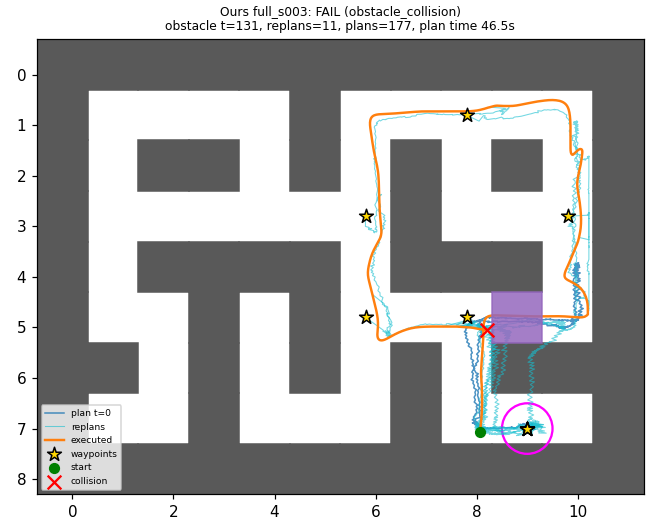

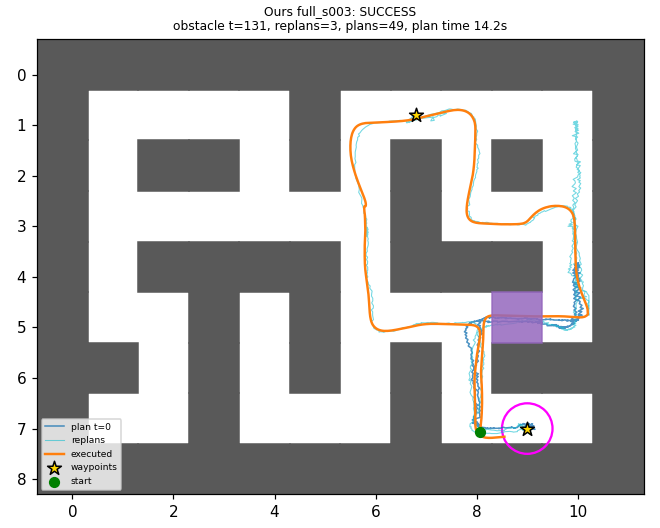

In [22]:
import json, glob
for f in sorted(glob.glob(f'{RESULTS}/ablation_junctions/Ours/episodes/*.json')):
    r = json.load(open(f))
    if r['obstacle_collision']:
        print(r['scenario_id'])
        for e in r['events']:
            if e['event'] in ('astar', 'segment', 'obstacle_collision'):
                print('   ', e)
        show(f[:-5] + '.png', 500)
        show(f"{RESULTS}/main/Ours/episodes/{r['scenario_id']}.png", 500)   # 同一情境的 greedy
        break

## C10. 消融二：waypoint 怎麼用（分段走 vs 中間 inpainting，proposal 貢獻 3）

`inpaint`：只產生一條計畫，在中間某一步只固定 waypoint 的 x、y（速度不固定）。模型訓練時沒看過這種條件。
**結果**：成功率 20%（分段走 76%），抽樣量 212（分段走 54）。9,728 條計畫中 **98.8% 在被固定的那一步出現尖刺**（瞬移到 waypoint 又跳回原路），只有 1.4% 可用。結論：不重新訓練的話，凍結的 Diffuser 無法把中間條件融入整條軌跡；分段走只固定每段頭尾，符合訓練時的條件。

In [25]:
%cd {REPO_DIR}
!$PY experiments/blocked/run_blocked.py --config {cfg('experiments/blocked/configs/ablation_inpaint.json')} --out {RESULTS}/ablation_inpaint
!$PY experiments/blocked/analyze_blocked.py {RESULTS}/ablation_inpaint

/content/diffuser-project

[Ours] full_s006        success=False stuck_on_wall        steps=800 replans=7 plans=113 astar=6 plan_time=34.2s
[Ours] full_s011        success=False stuck_on_wall        steps=800 replans=2 plans= 33 astar=1 plan_time=11.7s
[Ours] full_s012        success=False timeout_still_moving steps=800 replans=2 plans= 33 astar=1 plan_time=11.7s
[Ours] full_s014        success=False timeout_still_moving steps=800 replans=11 plans=177 astar=10 plan_time=46.7s
[Ours] full_s015        success=False stuck_on_wall        steps=800 replans=13 plans=209 astar=12 plan_time=53.5s
[Ours] full_s017        success=True                       steps=531 replans=6 plans= 97 astar=5 plan_time=26.5s
[Ours] full_s018        success=False timeout_still_moving steps=800 replans=37 plans=593 astar=36 plan_time=144.8s
[Ours] full_s019        success=False timeout_still_moving steps=800 replans=63 plans=1009 astar=62 plan_time=239.2s
[Ours] full_s021        success=True                      

In [26]:
import json, glob
ev = []
for f in sorted(glob.glob(f'{RESULTS}/ablation_inpaint/Ours/episodes/*.json')):
    ev += [e for e in json.load(open(f))['events'] if e['event'] == 'inpaint']
n = sum(e['n'] for e in ev)
print('inpaint calls', len(ev), '| plans', n)
print('kink (spike near waypoint):', sum(e['n_kink'] for e in ev), '/', n)
print('avoid obstacle:', sum(e['n_clear'] for e in ev), '/', n)
print('no wall tunnelling:', sum(e['n_wall_ok'] for e in ev), '/', n)
print('OK (usable):', sum(e['n_ok'] for e in ev), '/', n)

inpaint calls 608 | plans 9728
kink (spike near waypoint): 9608 / 9728
avoid obstacle: 185 / 9728
no wall tunnelling: 9164 / 9728
OK (usable): 132 / 9728


下面是前 3 個情境的軌跡圖。full_s003、full_s004 裡從路線直直射向星星的細線，就是計畫在被固定的那一步瞬移。

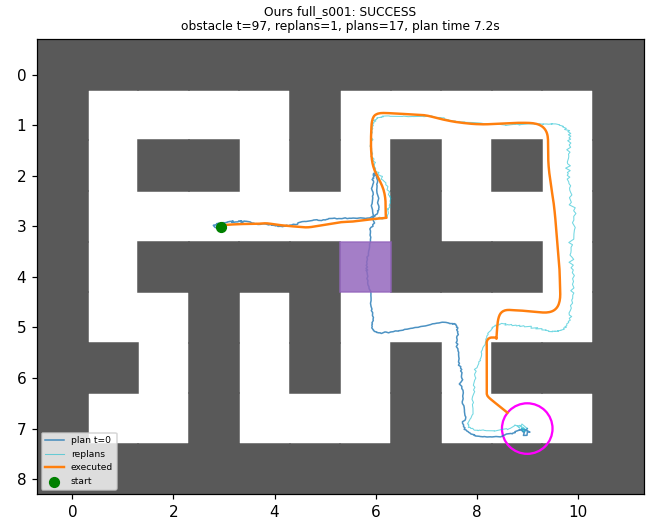

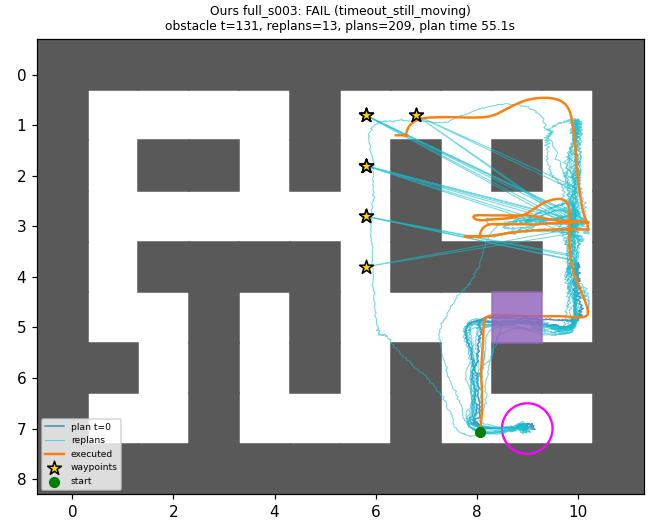

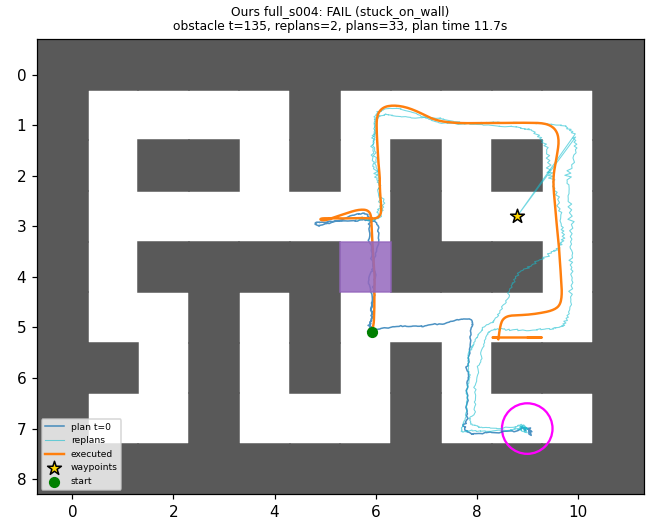

In [27]:
for p in sorted(glob.glob(f'{RESULTS}/ablation_inpaint/Ours/episodes/*.png'))[:3]:
    show(p, 450)

---
# 接下來

- 程式和結果已在 `xinyi/rerouting` branch，並向 Sirius 的 repo 發 PR；合併後把 B1 的 `BRANCH` 改成 `'main'`
- 報告的限制：只有一個迷宮、一個固定終點；障礙物集中在少數幾格；部分堵塞時預測觸發會誤報